In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import io

Dashboard visualization engine successfully run! Asset generated: dashboard_snapshot.png


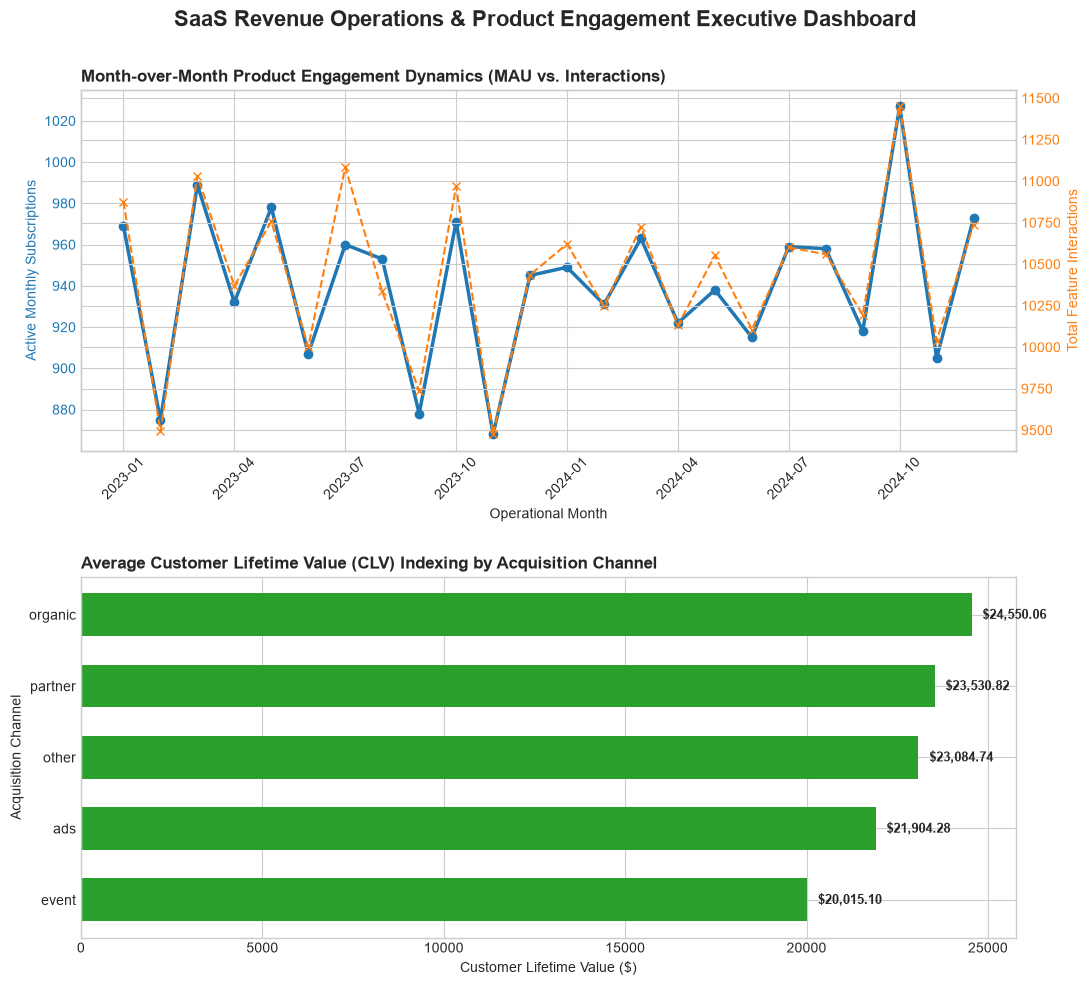

In [3]:
# 1. READ CHANNELS DATA (From sql_07_schema.sql output)
channel_data = """acquisition_channel	total_acquired_customers	total_realized_revenue	average_customer_lifetime_value
organic	114	2798707.0	24550.06
partner	89	2094243.0	23530.82
other	103	2377728.0	23084.74
ads	98	2146619.0	21904.28
event	96	1921450.0	20015.1"""
df_channel = pd.read_csv(io.StringIO(channel_data), sep='\t')

# 2. READ MAU DATA (From sql_05_schema.sql output)
mau_data = """operational_month	monthly_active_subscriptions	total_feature_interactions
2023-01	969	10877
2023-02	875	9492
2023-03	989	11031
2023-04	932	10369
2023-05	978	10757
2023-06	907	10002
2023-07	960	11083
2023-08	953	10335
2023-09	878	9737
2023-10	971	10968
2023-11	868	9475
2023-12	945	10435
2024-01	949	10621
2024-02	931	10247
2024-03	963	10725
2024-04	922	10131
2024-05	938	10552
2024-06	915	10106
2024-07	959	10601
2024-08	958	10559
2024-09	918	10195
2024-10	1027	11450
2024-11	905	10039
2024-12	973	10738"""
df_mau = pd.read_csv(io.StringIO(mau_data), sep='\t')

# 3. CONSTRUCT THE VISUAL DASHBOARD GRID
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
fig, axes = plt.subplots(2, 1, figsize=(11, 10))
fig.suptitle('SaaS Revenue Operations & Product Engagement Executive Dashboard', fontsize=16, fontweight='bold', y=0.98)

# Panel A: MAU Trend Line & Feature Usage Lifecycle
ax1 = axes[0]
color = '#1f77b4'
ax1.set_title('Month-over-Month Product Engagement Dynamics (MAU vs. Interactions)', fontsize=12, fontweight='bold', loc='left')
ax1.set_xlabel('Operational Month', fontsize=10)
ax1.set_ylabel('Active Monthly Subscriptions', color=color, fontsize=10)
line1 = ax1.plot(df_mau['operational_month'], df_mau['monthly_active_subscriptions'], color=color, marker='o', linewidth=2.5, label='Active Subscriptions')
ax1.tick_params(axis='y', labelcolor=color)
ax1.set_xticks(df_mau['operational_month'][::3])
ax1.set_xticklabels(df_mau['operational_month'][::3], rotation=45)

ax2 = ax1.twinx()  
color_secondary = '#ff7f0e'
ax2.set_ylabel('Total Feature Interactions', color=color_secondary, fontsize=10)
line2 = ax2.plot(df_mau['operational_month'], df_mau['total_feature_interactions'], color=color_secondary, marker='x', linestyle='--', linewidth=1.5, label='Feature Interactions')
ax2.tick_params(axis='y', labelcolor=color_secondary)

# Panel B: CAC/LTV Performance by Channel (CLV Profile Analytics)
ax3 = axes[1]
df_channel_sorted = df_channel.sort_values(by='average_customer_lifetime_value', ascending=True)
bars = ax3.barh(df_channel_sorted['acquisition_channel'], df_channel_sorted['average_customer_lifetime_value'], color='#2ca02c', edgecolor='none', height=0.6)
ax3.set_title('Average Customer Lifetime Value (CLV) Indexing by Acquisition Channel', fontsize=12, fontweight='bold', loc='left')
ax3.set_xlabel('Customer Lifetime Value ($)', fontsize=10)
ax3.set_ylabel('Acquisition Channel', fontsize=10)

# Add values directly to the horizontal bar endpoints
for bar in bars:
    width = bar.get_width()
    ax3.text(width + 300, bar.get_y() + bar.get_height()/2, f"${width:,.2f}", 
             va='center', ha='left', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.subplots_adjust(top=0.90, hspace=0.35)

# Save output asset directly into the dashboard portfolio directory
plt.savefig('dashboard_snapshot.png', dpi=300, bbox_inches='tight')
print("Dashboard visualization engine successfully run! Asset generated: dashboard_snapshot.png")